In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('WiFI_and_MQTT/balanced_dataset.csv')

In [3]:
df.head()

,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,Attack_Type,Label,Attack
0,695746.0,6.0,64.0,184.999355,184.999355,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,577.5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8217.0,1494.0,1494.0,1494.000000,0.000000,1494.0,1.667905e-03,5.5,54.662601,0.000000,0.000000,0.0,38.5,Spoofing,1,ARP Spoofing
1,3637961.1,17.0,64.0,173.228536,173.228536,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,2447.1,218.7,1144.0,534.579762,396.741844,347.9,6.082892e-03,5.5,32.138960,561.077696,175443.801999,0.9,38.5,Spoofing,1,ARP Spoofing
2,1702906.8,17.0,64.0,180.256940,180.256940,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1693.8,87.0,1034.8,302.935238,337.026851,262.4,6.571817e-03,5.5,24.147095,476.627944,140421.963059,0.9,38.5,Spoofing,1,ARP Spoofing
3,5339.5,6.0,119.0,0.088987,0.088987,0.0,0.0,0.0,0.0,0.5,1.0,0.0,0.0,0.0,0.0,0.0,70.1,0.0,0.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,476.5,55.2,111.6,83.336190,24.655715,84.3,9.981289e-02,5.5,12.879015,34.868446,729.505696,0.9,38.5,Spoofing,1,ARP Spoofing
4,2484636.8,17.0,64.0,180.866422,180.866422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,4405.8,102.6,686.0,284.489893,223.962943,304.0,1.694024e+08,13.5,23.888075,317.003649,50281.331821,1.0,244.6,Spoofing,1,ARP Spoofing


In [4]:
df.shape

(699409, 48)

In [5]:
df.duplicated().sum()

0

In [6]:
df = df.drop_duplicates()

In [7]:
df.shape

(8767634, 47)

In [6]:
df.isnull().any().any()

False

In [7]:
df.isnull().sum()

Header_Length      0
Protocol Type      0
Duration           0
Rate               0
Srate              0
Drate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
rst_count          0
HTTP               0
HTTPS              0
DNS                0
Telnet             0
SMTP               0
SSH                0
IRC                0
TCP                0
UDP                0
DHCP               0
ARP                0
ICMP               0
IGMP               0
IPv                0
LLC                0
Tot sum            0
Min                0
Max                0
AVG                0
Std                0
Tot size           0
IAT                0
Number             0
Magnitue           0
Radius             0
Covariance         0
Variance           0
Weight             0
Attack_Type        0
Label              0
Attack       

In [8]:
df.columns

Index(['Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'Attack_Type', 'Label', 'Attack'], dtype='object')

In [56]:
df = df.drop(['Attack_Type', 'Attack', 'Drate'], axis=1)

In [57]:
df['Label'].unique()

array([1, 0], dtype=int64)

<h2>Feature Selection </h2>

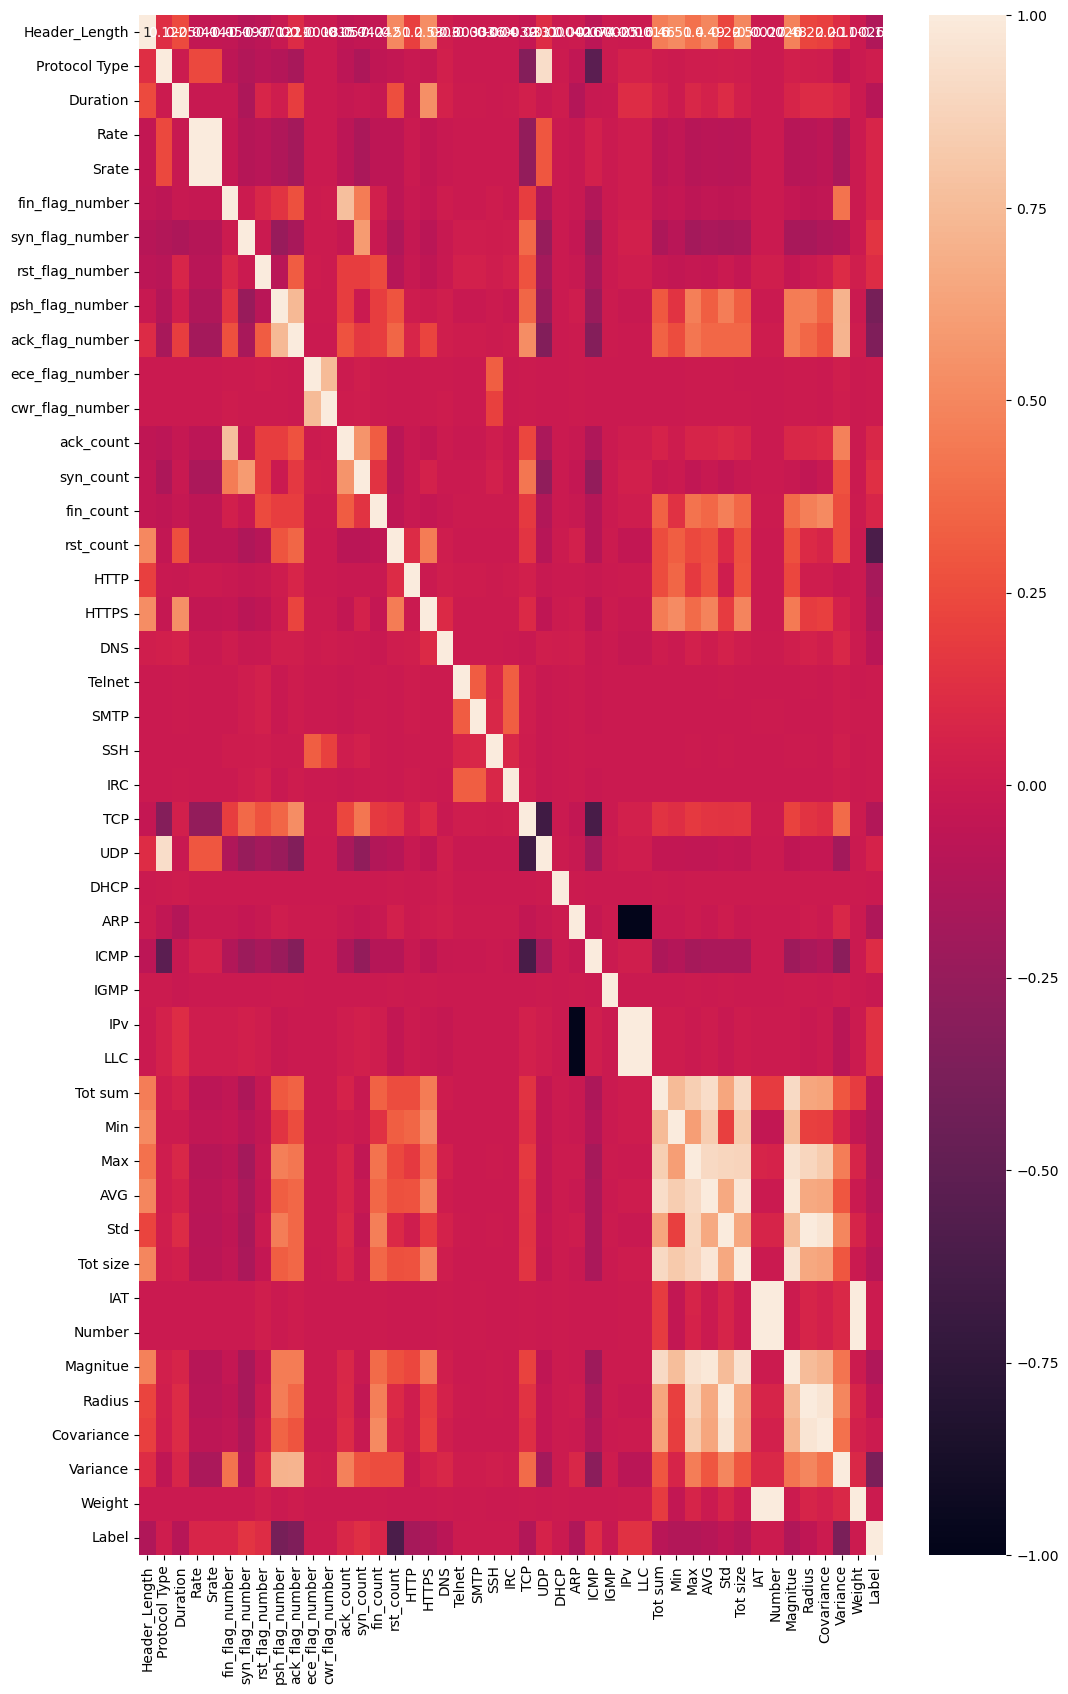

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize = (12, 20))
sns.heatmap(df.corr(), annot=True)
plt.show()

<h3>Mutual Information</h3>

In [59]:
from sklearn.feature_selection import mutual_info_classif
# Separate features and target
X = df.drop(columns=['Label'])
y = df['Label']
# Calculate mutual information

mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=0)

# Create a DataFrame to show results
mi_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})
mi_df = mi_df.sort_values(by='MI Score', ascending=False).reset_index(drop=True)
print("Top Features by Mutual Information:")
print(mi_df)

Top Features by Mutual Information:
            Feature  MI Score
0            Number  0.234509
1            Weight  0.219461
2               IAT  0.202621
3          Tot size  0.183682
4               Max  0.180283
5         rst_count  0.166100
6               Min  0.163527
7          Magnitue  0.161528
8               AVG  0.156165
9               TCP  0.154917
10            Srate  0.154638
11             Rate  0.154623
12          Tot sum  0.153848
13  psh_flag_number  0.151739
14         Duration  0.139299
15    Header_Length  0.134999
16         Variance  0.129548
17              LLC  0.121659
18              IPv  0.121197
19           Radius  0.113912
20    Protocol Type  0.113620
21       Covariance  0.113237
22              Std  0.112806
23  ack_flag_number  0.107715
24              UDP  0.049609
25  syn_flag_number  0.034429
26        fin_count  0.026586
27        syn_count  0.025504
28  rst_flag_number  0.021265
29            HTTPS  0.019982
30             ICMP  0.019399
31  

In [60]:
top_features = mi_df.head(40)['Feature'].tolist()
print("\n Best 40 Features:")
print(top_features)


 Best 40 Features:
['Number', 'Weight', 'IAT', 'Tot size', 'Max', 'rst_count', 'Min', 'Magnitue', 'AVG', 'TCP', 'Srate', 'Rate', 'Tot sum', 'psh_flag_number', 'Duration', 'Header_Length', 'Variance', 'LLC', 'IPv', 'Radius', 'Protocol Type', 'Covariance', 'Std', 'ack_flag_number', 'UDP', 'syn_flag_number', 'fin_count', 'syn_count', 'rst_flag_number', 'HTTPS', 'ICMP', 'ack_count', 'fin_flag_number', 'ARP', 'HTTP', 'DNS', 'Telnet', 'IGMP', 'ece_flag_number', 'cwr_flag_number']


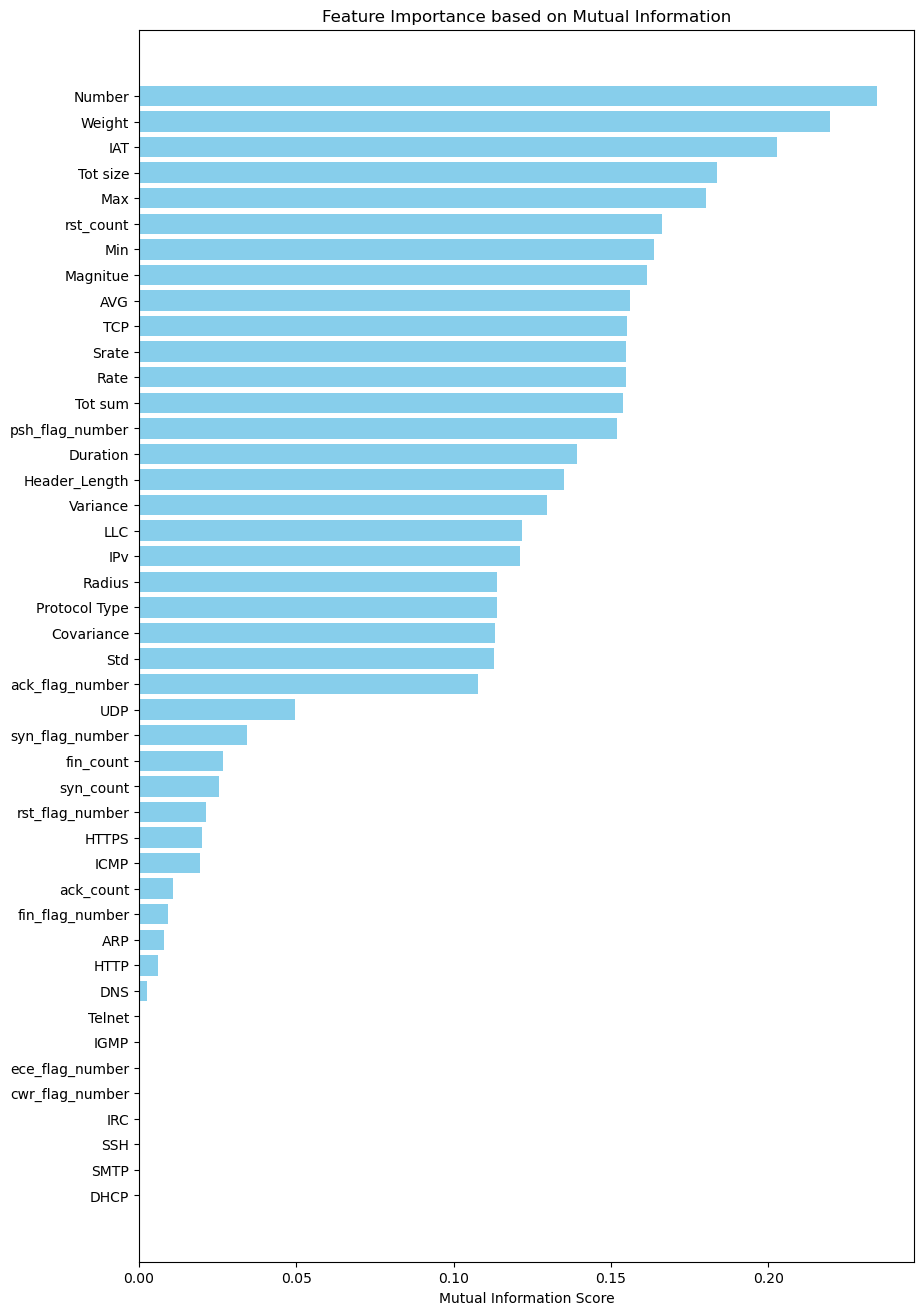

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 16))
plt.barh(mi_df['Feature'], mi_df['MI Score'], color='skyblue')
plt.xlabel("Mutual Information Score")
plt.title("Feature Importance based on Mutual Information")
plt.gca().invert_yaxis()
plt.show()

<h3>Decision Tree / Random Forest</h3>

Feature importances:
Feature 0 (Header_Length): 0.0879
Feature 1 (Protocol Type): 0.0037
Feature 2 (Duration): 0.0121
Feature 3 (Rate): 0.0757
Feature 4 (Srate): 0.0989
Feature 5 (fin_flag_number): 0.0006
Feature 6 (syn_flag_number): 0.0057
Feature 7 (rst_flag_number): 0.0051
Feature 8 (psh_flag_number): 0.0476
Feature 9 (ack_flag_number): 0.0102
Feature 10 (ece_flag_number): 0.0000
Feature 11 (cwr_flag_number): 0.0000
Feature 12 (ack_count): 0.0029
Feature 13 (syn_count): 0.0051
Feature 14 (fin_count): 0.0111
Feature 15 (rst_count): 0.1523
Feature 16 (HTTP): 0.0029
Feature 17 (HTTPS): 0.0069
Feature 18 (DNS): 0.0013
Feature 19 (Telnet): 0.0000
Feature 20 (SMTP): 0.0000
Feature 21 (SSH): 0.0000
Feature 22 (IRC): 0.0000
Feature 23 (TCP): 0.0026
Feature 24 (UDP): 0.0034
Feature 25 (DHCP): 0.0000
Feature 26 (ARP): 0.0010
Feature 27 (ICMP): 0.0002
Feature 28 (IGMP): 0.0000
Feature 29 (IPv): 0.0006
Feature 30 (LLC): 0.0018
Feature 31 (Tot sum): 0.0202
Feature 32 (Min): 0.0208
Feature 33 (Ma

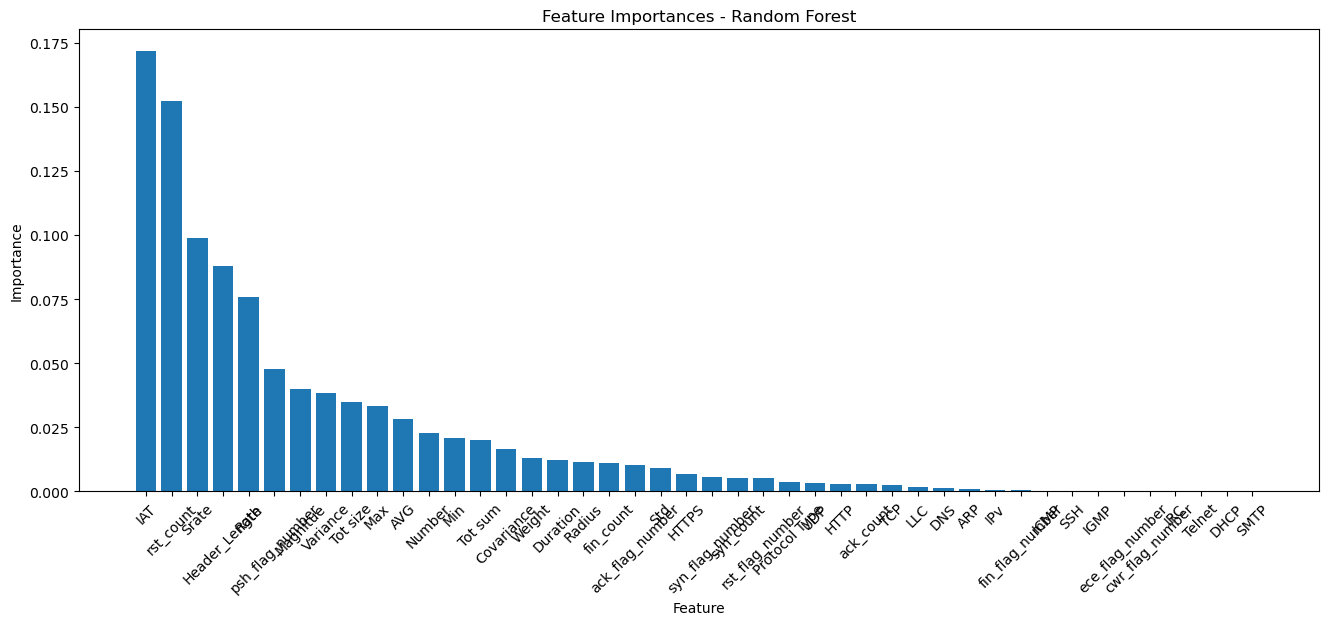

In [62]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
print("Feature importances:")
for i in range(X.shape[1]):
    print(f"Feature {i} ({df.columns[i]}): {importances[i]:.4f}")
plt.figure(figsize=(16, 6))
plt.title('Feature Importances - Random Forest')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), np.array(df.columns)[indices], rotation=45)
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.show()

<h2>Outliers</h2>

In [82]:
df2 = df.copy()

In [83]:
df2 = df2.drop(['IGMP', 'IRC', 'SSH', 'SMTP', 'DHCP', 'Telnet', 'cwr_flag_number'], axis=1)

In [84]:
df2.shape

(699409, 38)

In [85]:
df2["IAT"].unique()

array([1.66790485e-03, 6.08289242e-03, 6.57181740e-03, ...,
       1.46128178e-02, 1.25222707e-01, 1.69453273e+08])

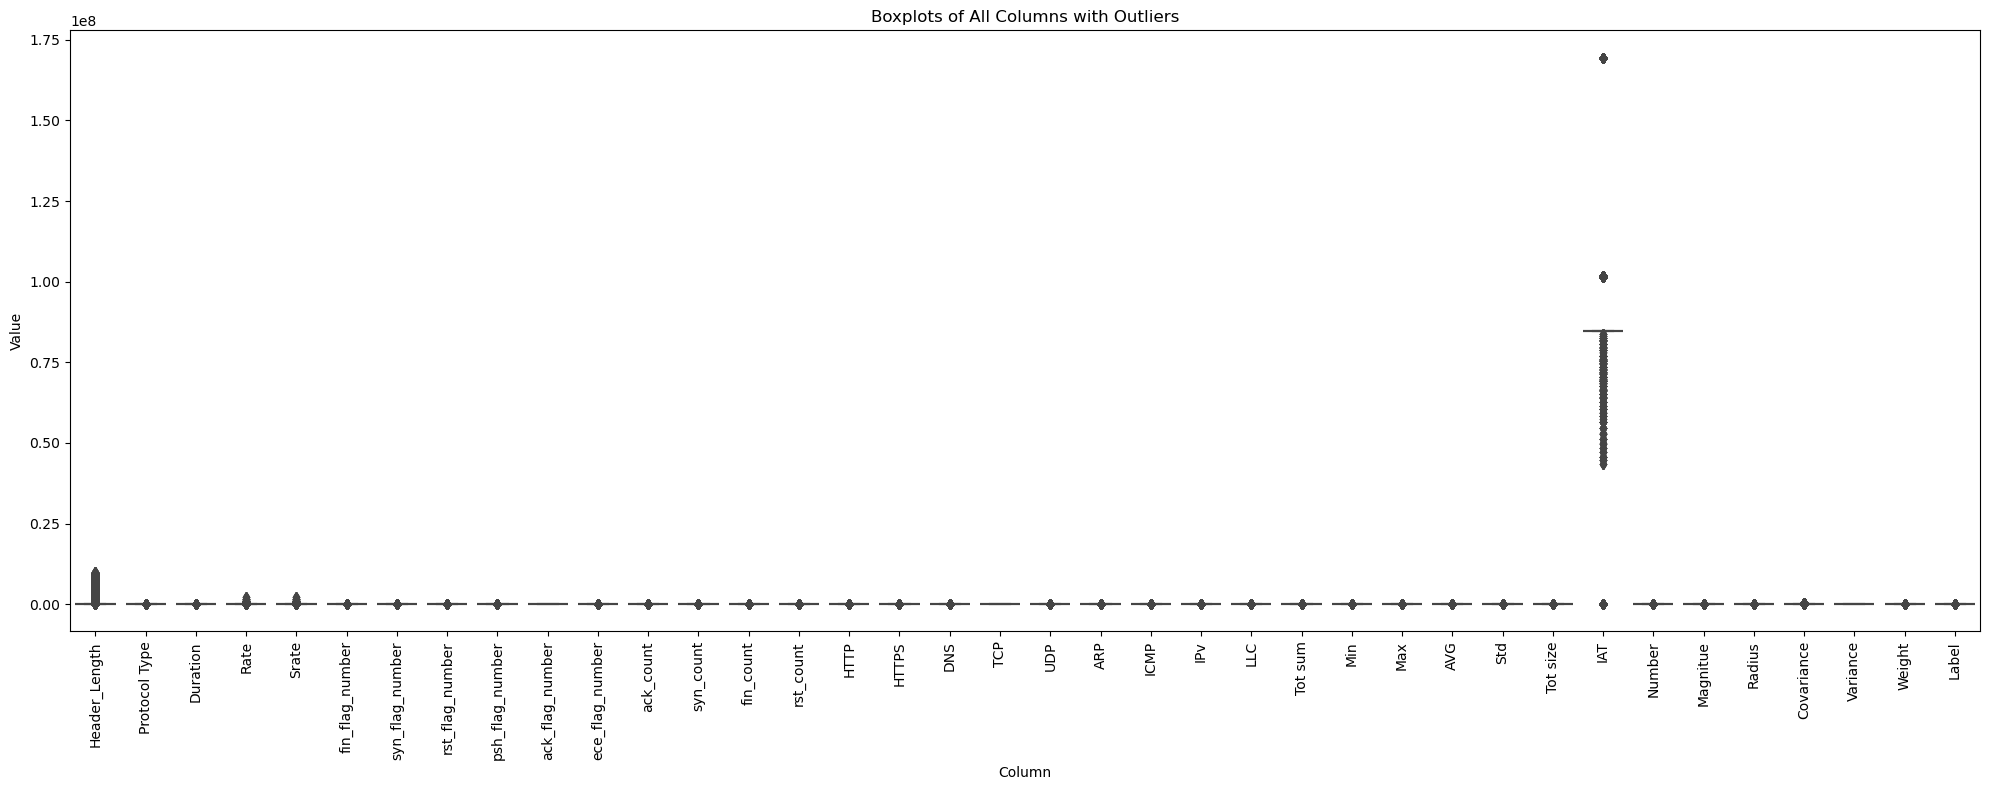

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.savefig("Graphs/outliers.pdf")   # <-- save as PDF
plt.show()

In [86]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [87]:
outliers_per_column

{'Header_Length': 85829,
 'Protocol Type': 255639,
 'Duration': 96835,
 'Rate': 153479,
 'Srate': 153479,
 'fin_flag_number': 81807,
 'syn_flag_number': 127119,
 'rst_flag_number': 173283,
 'psh_flag_number': 76002,
 'ack_flag_number': 0,
 'ece_flag_number': 211,
 'ack_count': 97887,
 'syn_count': 10449,
 'fin_count': 114115,
 'rst_count': 147680,
 'HTTP': 2889,
 'HTTPS': 38658,
 'DNS': 3306,
 'TCP': 0,
 'UDP': 160866,
 'ARP': 7281,
 'ICMP': 105416,
 'IPv': 7281,
 'LLC': 7281,
 'Tot sum': 117144,
 'Min': 90762,
 'Max': 138864,
 'AVG': 120572,
 'Std': 133343,
 'Tot size': 120304,
 'IAT': 148808,
 'Number': 148090,
 'Magnitue': 114424,
 'Radius': 133095,
 'Covariance': 151161,
 'Variance': 0,
 'Weight': 148125,
 'Label': 50000}

In [88]:
outliers_per_column.pop("Label")
outliers_per_column

{'Header_Length': 85829,
 'Protocol Type': 255639,
 'Duration': 96835,
 'Rate': 153479,
 'Srate': 153479,
 'fin_flag_number': 81807,
 'syn_flag_number': 127119,
 'rst_flag_number': 173283,
 'psh_flag_number': 76002,
 'ack_flag_number': 0,
 'ece_flag_number': 211,
 'ack_count': 97887,
 'syn_count': 10449,
 'fin_count': 114115,
 'rst_count': 147680,
 'HTTP': 2889,
 'HTTPS': 38658,
 'DNS': 3306,
 'TCP': 0,
 'UDP': 160866,
 'ARP': 7281,
 'ICMP': 105416,
 'IPv': 7281,
 'LLC': 7281,
 'Tot sum': 117144,
 'Min': 90762,
 'Max': 138864,
 'AVG': 120572,
 'Std': 133343,
 'Tot size': 120304,
 'IAT': 148808,
 'Number': 148090,
 'Magnitue': 114424,
 'Radius': 133095,
 'Covariance': 151161,
 'Variance': 0,
 'Weight': 148125}

In [71]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

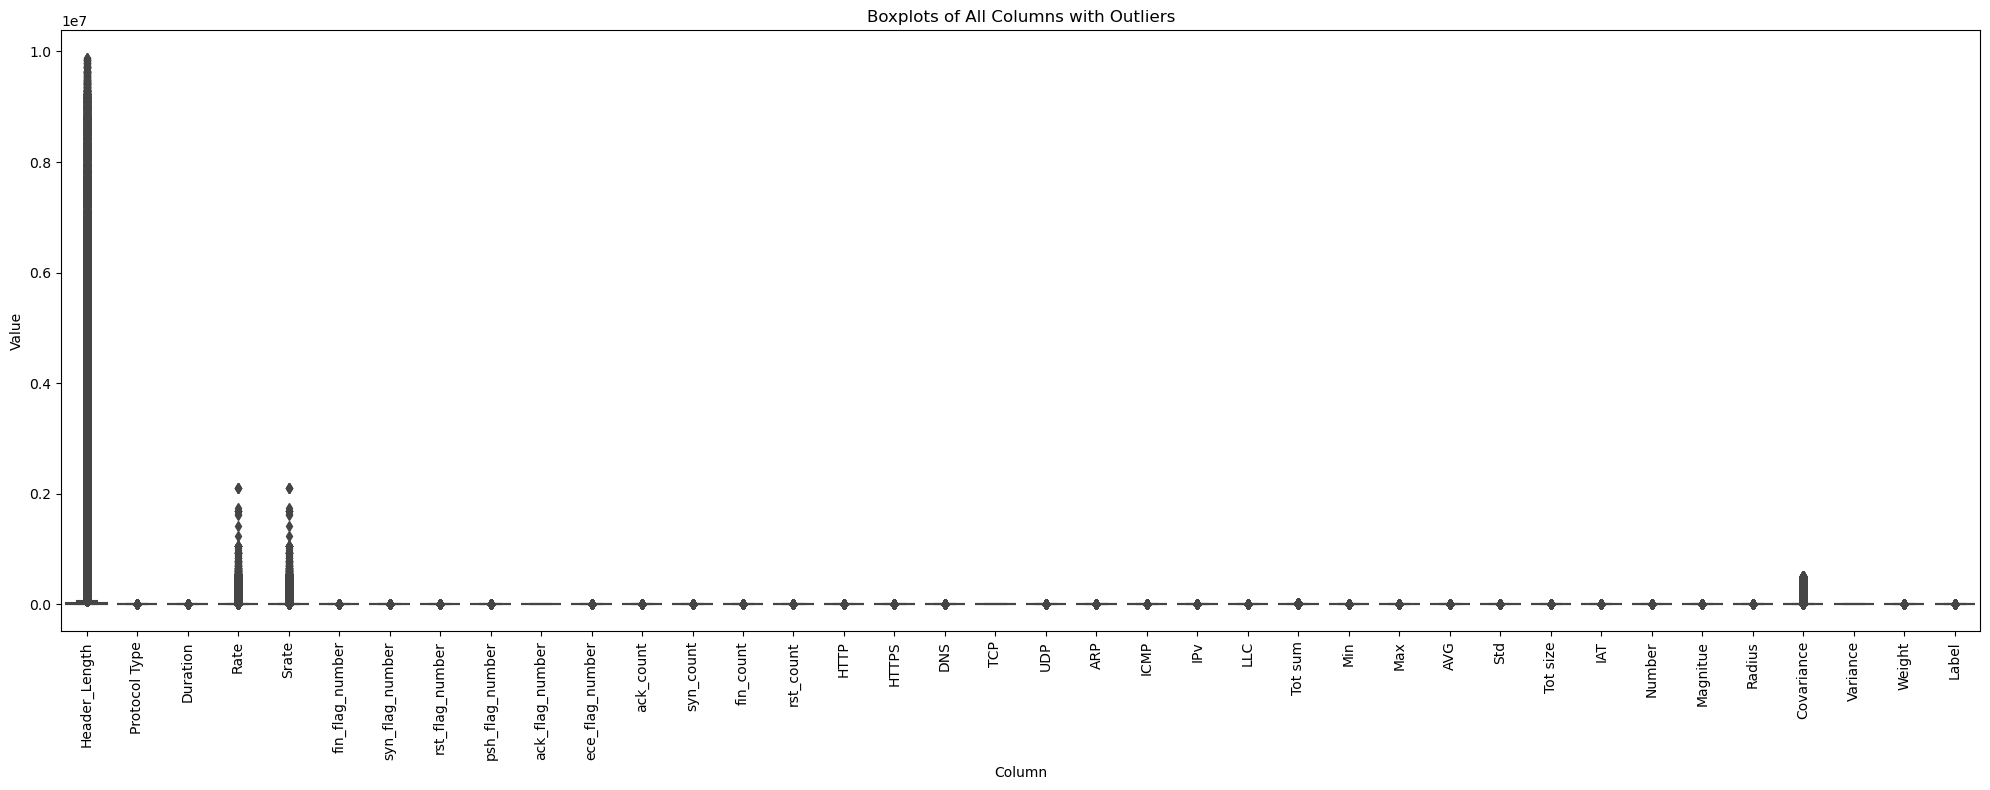

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.savefig("Graphs/outliers-removed.pdf")   # <-- save as PDF
plt.show()

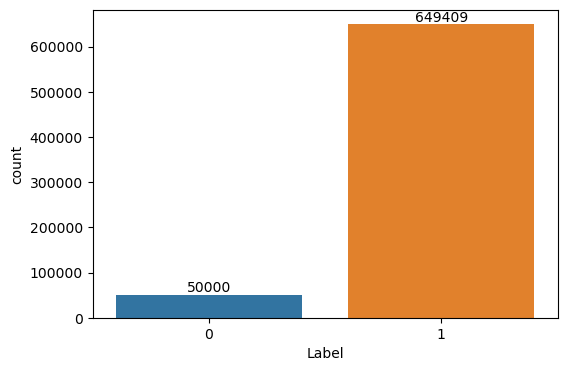

In [91]:
plt.figure(figsize=(6,4))
ax = sns.countplot(x='Label',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [92]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Label'])
y = df2['Label']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Label
1    519527
0     40000
Name: count, dtype: int64
Label
1    519527
0    519527
Name: count, dtype: int64


<h2>ML Models</h2>


🔹 Training Logistic Regression...
Logistic Regression Performance:
  Accuracy:  0.9793
  Precision: 0.9794
  Recall:    0.9793
  F1-score:  0.9794

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.86      0.86     10000
           1       0.99      0.99      0.99    129882

    accuracy                           0.98    139882
   macro avg       0.92      0.92      0.92    139882
weighted avg       0.98      0.98      0.98    139882



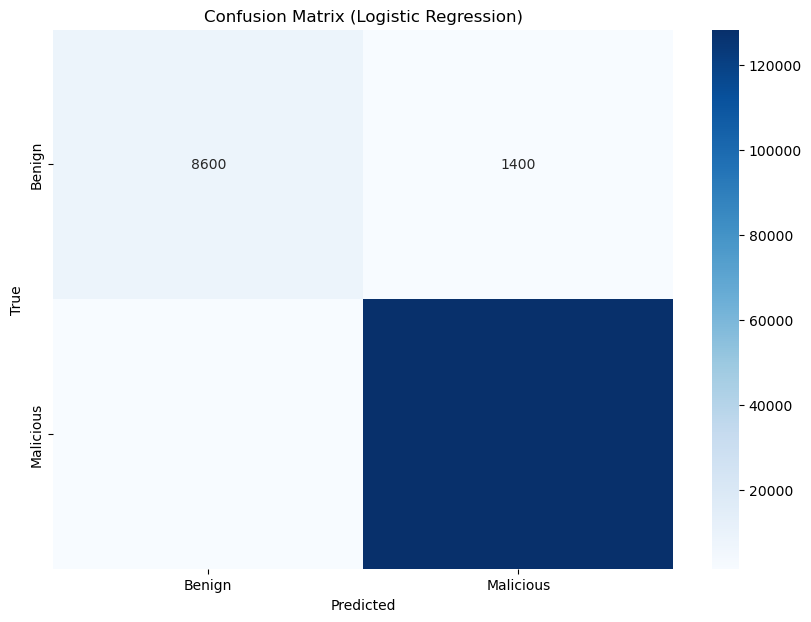


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.9925
  Precision: 0.9925
  Recall:    0.9925
  F1-score:  0.9925

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.94      0.95     10000
           1       1.00      1.00      1.00    129882

    accuracy                           0.99    139882
   macro avg       0.97      0.97      0.97    139882
weighted avg       0.99      0.99      0.99    139882



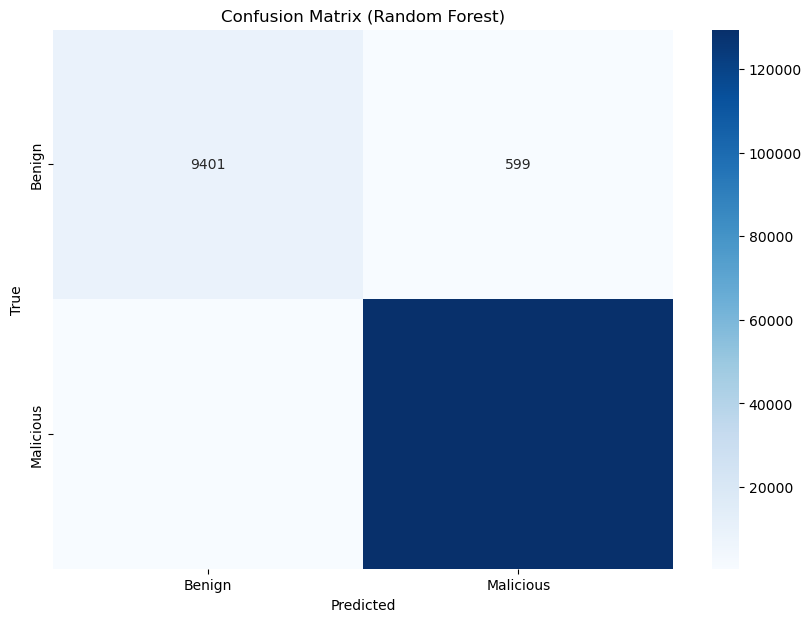


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:52:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.9927
  Precision: 0.9927
  Recall:    0.9927
  F1-score:  0.9927

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95     10000
           1       1.00      1.00      1.00    129882

    accuracy                           0.99    139882
   macro avg       0.98      0.97      0.97    139882
weighted avg       0.99      0.99      0.99    139882



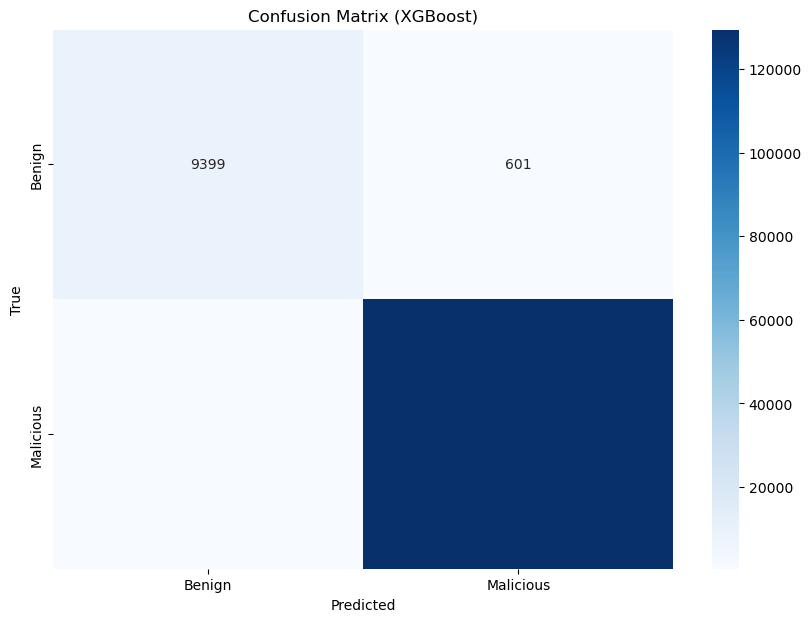


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.9862
  Precision: 0.9861
  Recall:    0.9862
  F1-score:  0.9862

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.90      0.90     10000
           1       0.99      0.99      0.99    129882

    accuracy                           0.99    139882
   macro avg       0.95      0.95      0.95    139882
weighted avg       0.99      0.99      0.99    139882



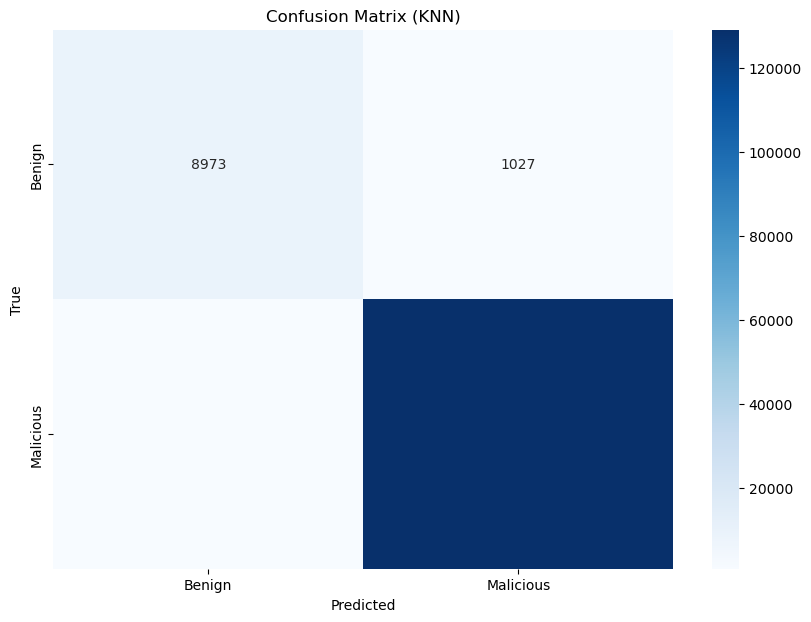


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.8795
  Precision: 0.9525
  Recall:    0.8795
  F1-score:  0.9025

Classification Report:
               precision    recall  f1-score   support

           0       0.37      0.97      0.54     10000
           1       1.00      0.87      0.93    129882

    accuracy                           0.88    139882
   macro avg       0.68      0.92      0.73    139882
weighted avg       0.95      0.88      0.90    139882



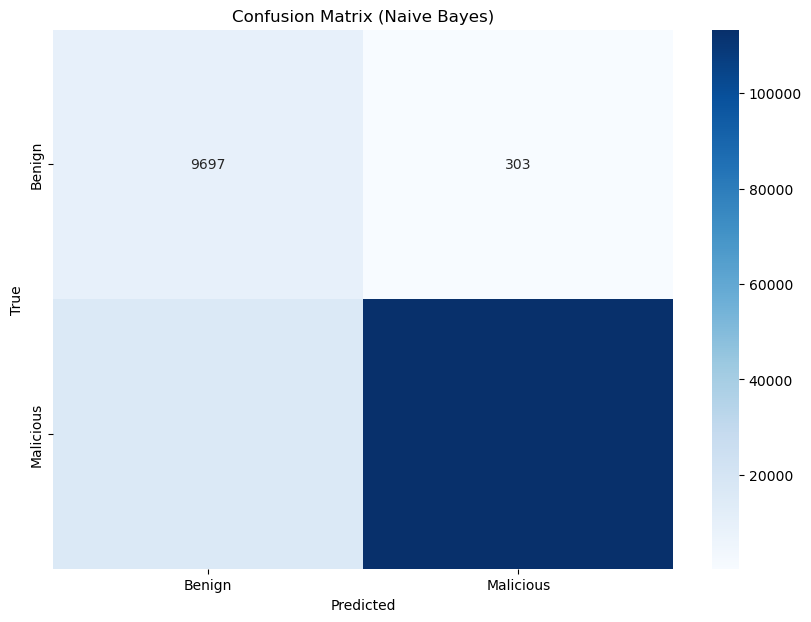


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.9892
  Precision: 0.9890
  Recall:    0.9892
  F1-score:  0.9891

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.90      0.92     10000
           1       0.99      1.00      0.99    129882

    accuracy                           0.99    139882
   macro avg       0.97      0.95      0.96    139882
weighted avg       0.99      0.99      0.99    139882



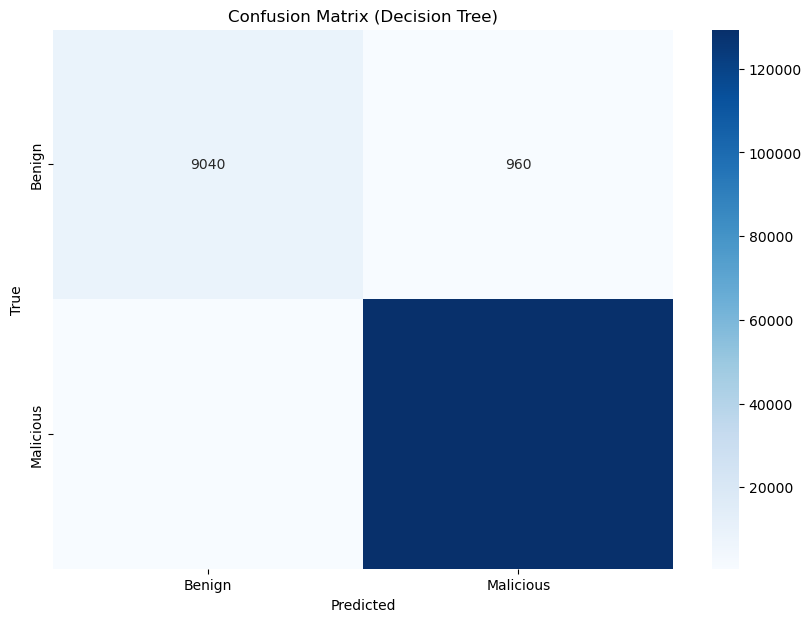


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.9790
  Precision: 0.9783
  Recall:    0.9790
  F1-score:  0.9784

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.80      0.84     10000
           1       0.98      0.99      0.99    129882

    accuracy                           0.98    139882
   macro avg       0.94      0.89      0.92    139882
weighted avg       0.98      0.98      0.98    139882



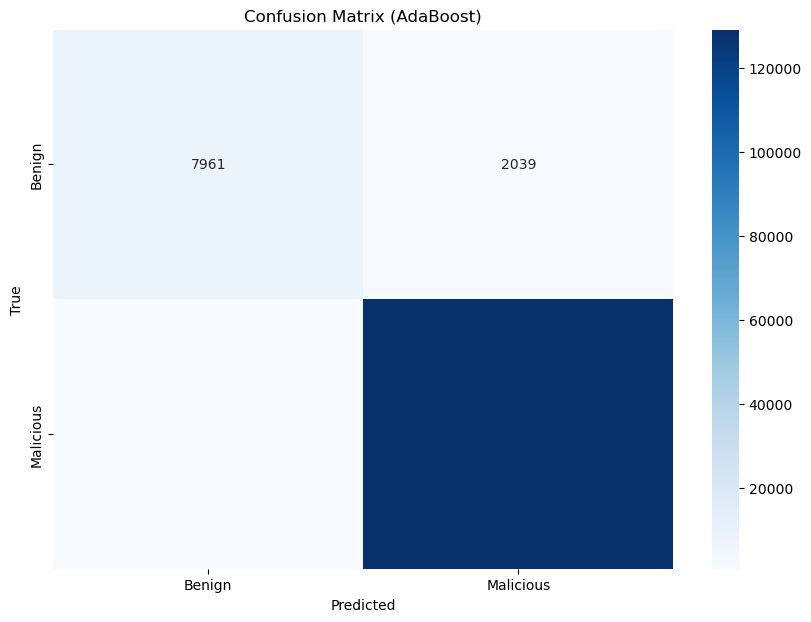


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.9915
  Precision: 0.9915
  Recall:    0.9915
  F1-score:  0.9915

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.93      0.94     10000
           1       0.99      1.00      1.00    129882

    accuracy                           0.99    139882
   macro avg       0.97      0.97      0.97    139882
weighted avg       0.99      0.99      0.99    139882



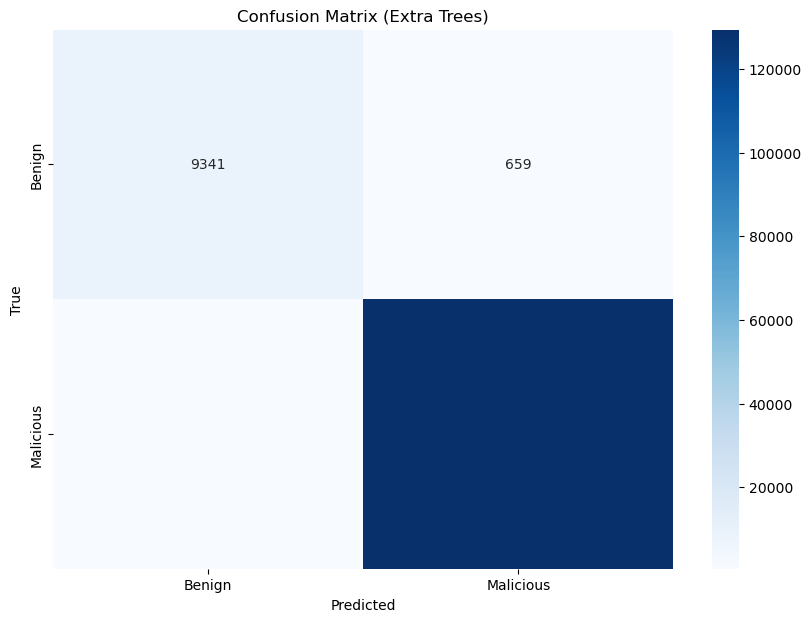


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.9928
  Precision: 0.9927
  Recall:    0.9928
  F1-score:  0.9928

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95     10000
           1       1.00      1.00      1.00    129882

    accuracy                           0.99    139882
   macro avg       0.98      0.97      0.97    139882
weighted avg       0.99      0.99      0.99    139882



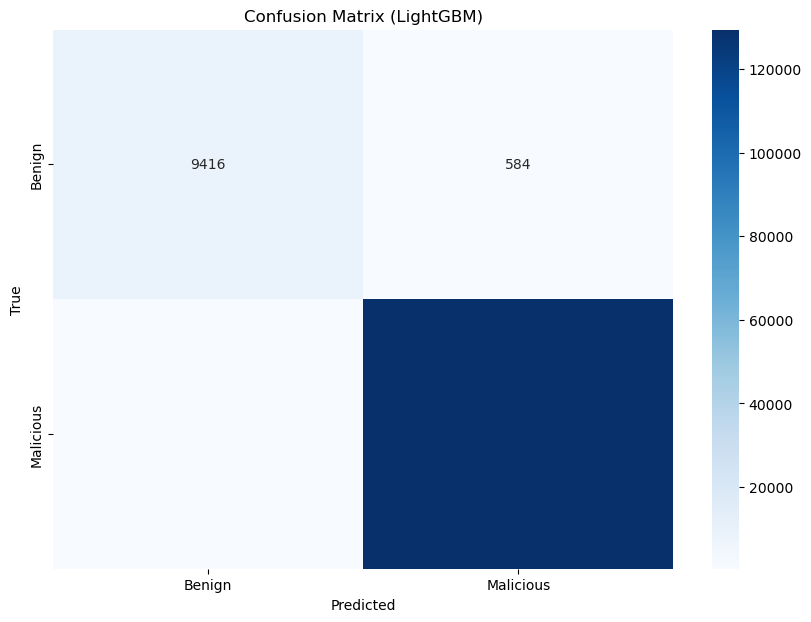


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.9914
  Precision: 0.9913
  Recall:    0.9914
  F1-score:  0.9913

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.93      0.94     10000
           1       0.99      1.00      1.00    129882

    accuracy                           0.99    139882
   macro avg       0.97      0.96      0.97    139882
weighted avg       0.99      0.99      0.99    139882



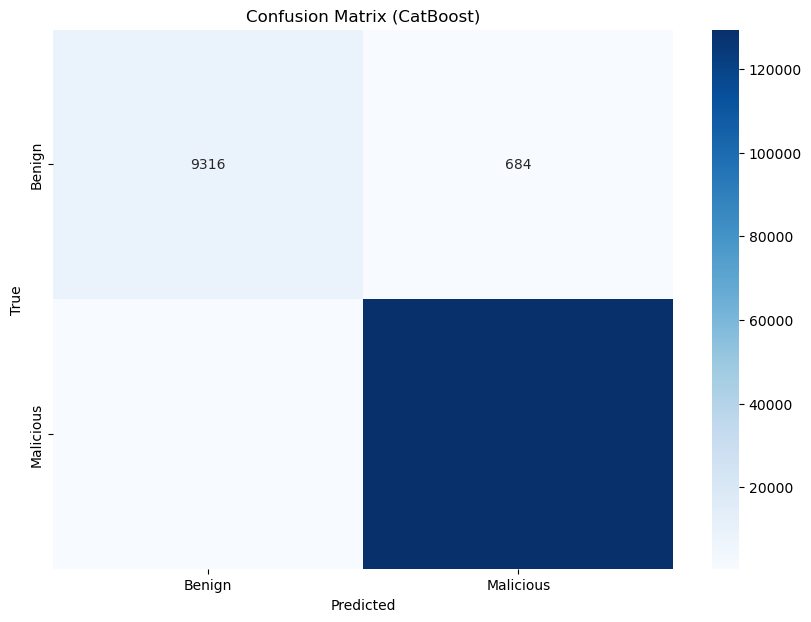


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.979340   0.979428  0.979340  0.979382
Random Forest        0.992515   0.992471  0.992515  0.992489
XGBoost              0.992701   0.992652  0.992701  0.992670
KNN                  0.986224   0.986149  0.986224  0.986183
Naive Bayes          0.879548   0.952451  0.879548  0.902523
Decision Tree        0.989155   0.989009  0.989155  0.989052
AdaBoost             0.979018   0.978319  0.979018  0.978428
Extra Trees          0.991521   0.991476  0.991521  0.991495
LightGBM             0.992780   0.992736  0.992780  0.992753
CatBoost             0.991357   0.991302  0.991357  0.991325


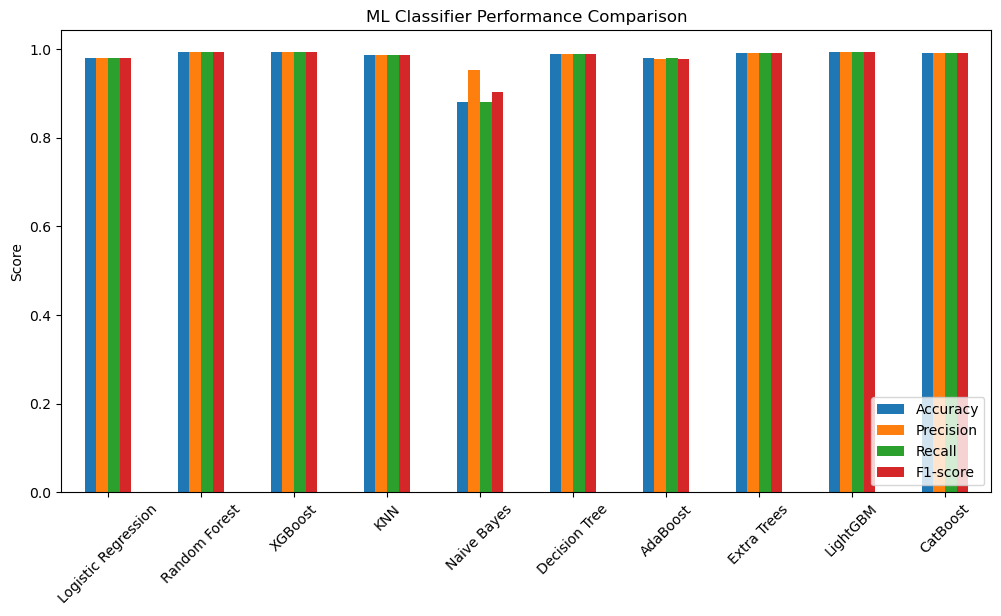

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = ['Benign', 'Malicious']

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"Graphs/Binary-ml-{name}.pdf")   # <-- save as PDF
    plt.show()

# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("Graphs/Binary-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...
Logistic Regression Avg Performance:
  Accuracy:  0.9794
  Precision: 0.9795
  Recall:    0.9794
  F1-score:  0.9794

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.9926
  Precision: 0.9926
  Recall:    0.9926
  F1-score:  0.9926

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [20:42:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [20:42:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [20:42:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [20:43:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.9924
  Precision: 0.9923
  Recall:    0.9924
  F1-score:  0.9923

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.9863
  Precision: 0.9863
  Recall:    0.9863
  F1-score:  0.9863

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.8804
  Precision: 0.9525
  Recall:    0.8804
  F1-score:  0.9031

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.9887
  Precision: 0.9885
  Recall:    0.9887
  F1-score:  0.9886

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.9787
  Precision: 0.9781
  Recall:    0.9787
  F1-score:  0.9782

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Performance:
  Accuracy:  0.9915
  Precision: 0.9915
  Recall:    0.9915
  F1-score:  0.9915

🔹 Training LightGBM with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.9927
  Precision: 0.9926
  Recall:    0.9927
  F1-score:  0.9927

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.9912
  Precision: 0.9912
  Recall:    0.9912
  F1-score:  0.9912

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.979391   0.979494  0.979391  0.979440
Random Forest        0.992608   0.992568  0.992608  0.992585
XGBoost              0.992379   0.992331  0.992379  0.992350
KNN                  0.986338   0.986278  0.986338  0.986306
Naive Bayes          0.880432   0.952519  0.880432  0.903148
Decision Tree        0.988698   0.988527  0.988698  0.988569
AdaBoost             0.978686   0.978074  0.978686  0.978245
Extra Trees          0.991513   0.991480  0.991513  0.991495
LightGBM             0.992682   0.992644  0.992682  0.992660
CatBoost             0.991234   0.991172  0.991234  0.991196


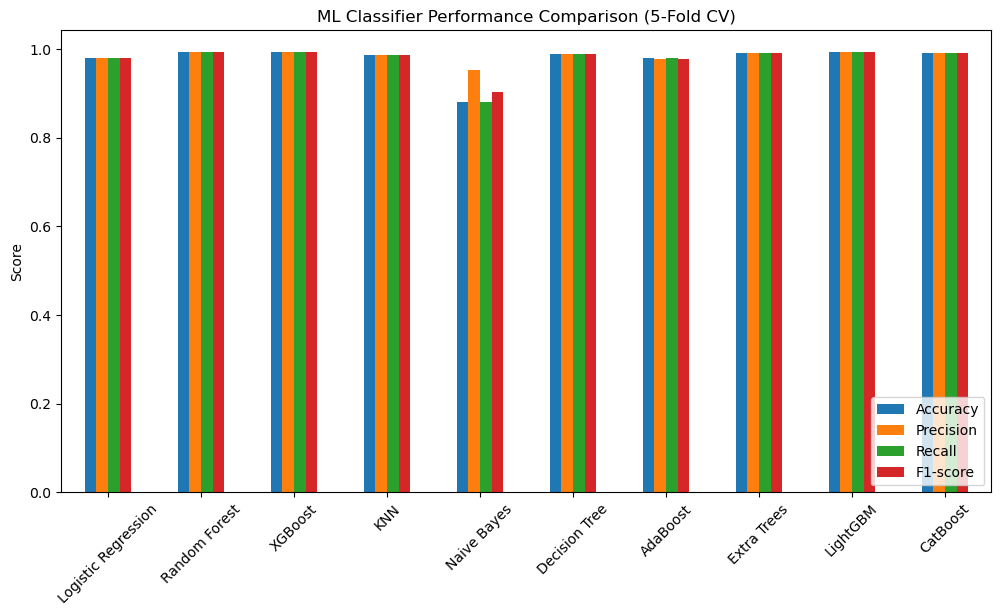

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, 
                             use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"Graphs/Binary-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("Graphs/Binary-ml-compare-5fold.pdf")
plt.show()
